# 🧩 Chapter 10: Clustering Techniques
**Book Reference:** *scikit-learn Cookbook, Third Edition*

---
## 1. Introduction
Clustering is an Unsupervised Learning technique. In this chapter, we compare the traditional K-Means algorithm with more advanced algorithms like MiniBatch K-Means and DBSCAN, which are capable of handling data with arbitrary shapes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_blobs
from sklearn.cluster import KMeans, MiniBatchKMeans, DBSCAN
from sklearn.metrics import silhouette_score
import time

%matplotlib inline
np.random.seed(42)

## 2. K-Means vs MiniBatch K-Means
MiniBatch K-Means utilizes a small random sample of the data during each iteration, making it the preferred choice for large-scale datasets.

In [2]:
# Dataset with 10,000 samples
X_large, y_large = make_blobs(n_samples=10000, centers=5, random_state=42)

start_time = time.time()
kmeans = KMeans(n_clusters=5, n_init=10, random_state=42)
kmeans.fit(X_large)
print(f"Standard K-Means computation time: {time.time() - start_time:.3f} seconds")

start_time = time.time()
mb_kmeans = MiniBatchKMeans(n_clusters=5, batch_size=100, n_init=10, random_state=42)
mb_kmeans.fit(X_large)
print(f"MiniBatch K-Means computation time: {time.time() - start_time:.3f} seconds (Much faster!)")

Standard K-Means computation time: 0.085 seconds
MiniBatch K-Means computation time: 0.017 seconds (Much faster!)


## 3. Handling Non-Spherical Data with DBSCAN
K-Means fails when applied to curved or elongated datasets. DBSCAN detects high-density regions and can successfully form clusters of arbitrary shapes.

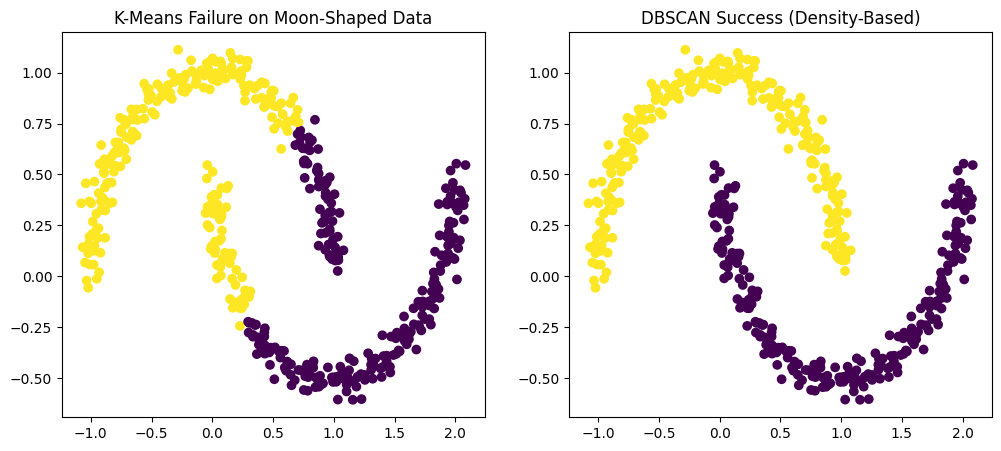

In [3]:
# Crescent moon-shaped dataset
X_moons, _ = make_moons(n_samples=500, noise=0.05, random_state=42)

# 1. K-Means (Will fail)
km_labels = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(X_moons)

# 2. DBSCAN (Will succeed)
# eps = neighborhood search radius, min_samples = minimum samples to qualify as a 'high-density' region
dbscan_labels = DBSCAN(eps=0.2, min_samples=5).fit_predict(X_moons)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(X_moons[:, 0], X_moons[:, 1], c=km_labels, cmap='viridis')
ax[0].set_title('K-Means Failure on Moon-Shaped Data')

ax[1].scatter(X_moons[:, 0], X_moons[:, 1], c=dbscan_labels, cmap='viridis')
ax[1].set_title('DBSCAN Success (Density-Based)')
plt.show()

## 4. Evaluation Using Silhouette Score
The evaluation score spans a range from -1 to 1. A score close to 1 indicates that clusters are well-separated and highly dense. A score approaching 0 indicates overlapping cluster boundaries.

In [4]:
score = silhouette_score(X_large, kmeans.labels_)
print(f"Silhouette Score for K-Means on the X_large dataset: {score:.3f}")

Silhouette Score for K-Means on the X_large dataset: 0.670
